# Лекция. Scikit-learn: сравнение моделей и итоговая проверка


В пятой работе была одна линейная модель: год, потом четыре числа, ошибка на valid. Сегодня вопрос другой. **Какой способ оценки цены на этих же данных врёт меньше?**

Меняем по одному элементу: алгоритм или его ручку. Таблицу, признаки и разрез 60/20/20 не трогаем. Иначе сравниваем разные экзамены и сами не понимаем, кто выиграл.

Договоримся о словах на всю пару.

**Модель** — правило, которое по признакам выдаёт цену. Сегодня их пять, у каждой полное имя.

- **Константа по медиане**, класс `DummyRegressor`. Всем одна цена.
- **Линейная регрессия**, класс `LinearRegression`. Одна формула на всех.
- **Метод k ближайших соседей**, класс `KNeighborsRegressor`. Средняя цена похожих машин.
- **Дерево решений**, класс `DecisionTreeRegressor`. Цепочка вопросов «да/нет», внизу одна цена.
- **Случайный лес**, класс `RandomForestRegressor`. Много деревьев, их цены усредняют.

Как каждая считает, разбираем в своём пункте. Дальше короткое слово — это то же имя, не новая модель.

**Гиперпараметр** — ручка, которую крутит человек **до** `fit`. Число соседей у `KNeighborsRegressor`, глубина у `DecisionTreeRegressor`, число деревьев у `RandomForestRegressor`. Модель сама её из цен не вычисляет.

**Переобучение** — правило слишком хорошо запомнило учебные строки и на новых машинах врёт сильнее. На train ошибка маленькая, на valid — большая.

**Valid** сегодня — место, где сравниваем варианты. **Test** открываем один раз в разделе 7, когда вариант уже выбран. После цифр теста ручки назад не крутим.

Идём по блокноту. Ячейки запускаем вместе. Ядро новое: переменные из пятой работы сюда не переносятся.


## 1. Восстанавливаем те же данные и части

Почему не «просто продолжить ноутбук 05»? Там в памяти уже лежат обученные модели и случайные куски. Если студент открыл 06 в другом сеансе, тех переменных нет. Поэтому 06 собирает всё заново и **тем же жребием**. `random_state=42` и `43`, тот же порядок: сначала 40% в сторону, потом эти 40% пополам. Тогда train, valid и test — те же строки, что в пятой работе, если файл тот же.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import sklearn

print('scikit-learn:', sklearn.__version__)


ModuleNotFoundError: No module named 'pandas'

Импорт ничего не учит. Моделей ещё нет. `mean_absolute_error` — знакомая MAE в евро. `mean_squared_error` и `r2_score` понадобятся на финальном тесте. `DummyRegressor` — полное имя этой заглушки: **регрессор-заглушка**. С `strategy='median'` он всем машинам называет одну цену, медиану train, и на признаки не смотрит. База, с которым потом сравниваем остальные модели.


In [3]:
data_path = Path('cars_processed.csv')
if data_path.exists():
    df = pd.read_csv(data_path)
else:
    df = pd.read_csv(
        'https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/'
        'refs/heads/main/Workshops/cars_processed.csv'
    )
df = df.rename(columns={'Price(euro)': 'Price', 'Engine_capacity(cm3)': 'Engine'})
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed:')])
df = df.reset_index(drop=True)
NUMERIC_FEATURES = ['Year', 'Distance', 'Engine', 'km_year']
if df[NUMERIC_FEATURES + ['Price']].isna().any().any():
    raise ValueError('В выбранных колонках есть пропуски: вернитесь к подготовке данных.')
if not np.isfinite(df[NUMERIC_FEATURES + ['Price']].to_numpy()).all():
    raise ValueError('В выбранных колонках есть бесконечные значения.')
if not (df['Price'] > 0).all():
    raise ValueError('Для этого учебного примера нужны положительные цены.')
df.head(3)


NameError: name 'pd' is not defined

Четыре входа, как в 05: год, пробег, объём, километры в год. Цена — ответ, в список признаков не входит. Три проверки те же: пустая клетка, бесконечность, цена не положительная. Красная ячейка — к модели не идём.

На экране три первые строки. Глазами: это тот же файл, евро, без новой формулы для цены.


In [4]:
X = df[NUMERIC_FEATURES].copy()
y = df['Price'].copy()

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.4, random_state=42
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, random_state=43
)

print('Train:', X_train.shape, 'Valid:', X_valid.shape, 'Test:', X_test.shape)


NameError: name 'df' is not defined

Коротко, потому что это уже было. Первый вызов: вся таблица → 60% train и 40% holdout. Второй: **только** holdout пополам → valid и test, примерно по 20%. Train во второй вызов не передаём. `test_size=0.4` в первом вызове — доля второй кучи, ещё не финальный экзамен.

Три числа на экране. Сумма строк train + valid + test равна числу строк `X`. Если файл другой или строки переставлены до разреза, куски уже не те, что в чужом отчёте по 05.

ВОПРОС: по какой части можно выбирать глубину дерева, по какой нельзя.


## 2. Pipeline: соединяем преобразование и модель

В пятой работе масштабирование было руками. Обучили `StandardScaler` на train, сделали `transform` для train и отдельно для valid, и только потом `LinearRegression`. На новой строке легко забыть `transform` или обучить второй scaler на valid. Второй вариант — утечка: экзамен успел повлиять на среднее.

**линейная регрессия**, класс `LinearRegression`. Она подбирает одну формулу на всех: свободный член плюс «коэффициент × признак» по каждому столбцу. Год вырос на единицу — прогноз меняется на коэффициент года. Так же для пробега, объёма и km_year. Коэффициенты считаются на train. На `predict` в формулу подставляют числа новой машины и получают евро. Отдельные учебные строки она не хранит.

`Pipeline` — конвейер из шагов в одном объекте. Мы отдаём таблицу в исходных единицах: год около 2010, пробег в километрах. Внутри шаги сами делают свою работу.

Как читать таблицу в ноутбуке.

На `fit` первый шаг, scaler, видит обучающие строки и запоминает среднее и разброс. Последний шаг, модель, учится уже на преобразованных числах.

На `predict` новая строка проходит тот же конвейер: scaler применяет **уже запомненные** среднее и разброс, модель выдаёт цену. Отдельный массив «scaled» нам наружу не нужен.

Имена шагов `'scale'` и `'model'` придумываем сами. Это бирки на коробках, не команды Python.


In [5]:
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearRegression())
])
linear_pipeline


ModuleNotFoundError: No module named 'sklearn'

Список пар читается сверху вниз. Создание объекта данные не видит. На экране схема из двух шагов. Средних и коэффициентов ещё нет: `fit` не вызывали.


In [5]:
linear_pipeline.fit(X_train, y_train)
linear_valid_pred = linear_pipeline.predict(X_valid)
linear_valid_mae = mean_absolute_error(y_valid, linear_valid_pred)
print(f'Линейная модель: Valid MAE = {linear_valid_mae:.1f} евро')


Линейная модель: Valid MAE = 4307.8 евро


`fit` получает сырой `X_train` и цены. В `predict` тоже сырой `X_valid`, без заранее посчитанного масштаба. Если студент сначала сам прогонит valid через scaler, а потом отдаст это в pipeline, масштабирование случится дважды: числа станут «странными стандартными единицами от уже стандартных», прогноз уедет.

Число MAE записываем. Это та же валидация, на ней дальше будут метод k ближайших соседей, дерево решений и случайный лес.

На этом прогоне Valid MAE линейной модели около **4307.8** евро. Медиана на той же valid позже будет около 5944: четыре признака полезнее, чем одна цена на всех.


## 3. Ближайшие соседи: учимся на похожих автомобилях

Полное имя: **метод k ближайших соседей**, класс `KNeighborsRegressor`. Буква k обозначает сколько соседей берём.

В Линейной регрессии берется одна формула на всех: «год плюс один → прибавь столько-то евро». Соседи формулу не строят.

Новую машину сравнивают с **обучающими** строками. Считают расстояние по признакам, берут k самых близких и, по умолчанию, усредняют их цены. Прогноз — «сколько стоили похожие из учебной кучи». На `fit` модель запоминает учебные строки и их цены. На `predict` она ищет соседей только среди них.

«Похожие» здесь не «та же модель глазами человека». Это расстояние по четырём числам. Год, пробег, объём, km_year. Марки в этом разделе нет.

Зачем scaler. Пробег сотни тысяч, год около двух тысяч. Без перевода в общий масштаб расстояние почти целиком про пробег: разница в 50 000 км перекричит разницу в десять лет. `StandardScaler` перед соседями как раз убирает эту несправедливость единиц. Для дерева ниже масштаб не нужен, для соседей нужен. Поэтому соседи живут внутри `Pipeline`, дерево — отдельным объектом.

`n_neighbors` — гиперпараметр. Человек говорит «смотри на 10 машин» до обучения. Из цен это число само не находится.


In [6]:
from sklearn.neighbors import KNeighborsRegressor

knn10 = Pipeline([
    ('scale', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=10))
])
knn10.fit(X_train, y_train)
knn10_valid_pred = knn10.predict(X_valid)
print(f'10 соседей: Valid MAE = {mean_absolute_error(y_valid, knn10_valid_pred):.1f} евро')


10 соседей: Valid MAE = 2721.1 евро


Те же valid-строки, что у линейной модели. Десять соседей дают около **2721.1** евро, линейная — **4307.8**. Разница примерно 1600 евро: на этих четырёх числах «похожее объявление» ближе к правде, чем одна прямая. Это ещё не конец сравнения: впереди дерево, лес и другие числа соседей.


In [7]:
one_car = X_valid.iloc[[0]]
one_scaled = knn10.named_steps['scale'].transform(one_car)
distances, positions = knn10.named_steps['model'].kneighbors(one_scaled)
neighbors = X_train.iloc[positions[0]].copy()
neighbors['Price'] = y_train.iloc[positions[0]].to_numpy()
neighbors['Distance_in_feature_space'] = distances[0]
display(one_car)
display(neighbors)
print('Средняя цена соседей:', neighbors['Price'].mean())
print('Прогноз:', knn10.predict(one_car)[0])


,Year,Distance,Engine,km_year
10010,2010,180000.0,1500.0,15000.0


,Year,Distance,Engine,km_year,Price,Distance_in_feature_space
31877,2010,180000.0,1500.0,15000.000000,6200.0,0.000000
31463,2010,180000.0,1500.0,15000.000000,6800.0,0.000000
19543,2010,180000.0,1500.0,15000.000000,6999.0,0.000000
11744,2010,180000.0,1500.0,15000.000000,5500.0,0.000000
32029,2010,180001.0,1500.0,15000.083333,5555.0,0.000014
30324,2010,179000.0,1500.0,14916.666667,5500.0,0.014397
4321,2010,178096.0,1500.0,14841.333333,4550.0,0.027413
4381,2010,178000.0,1500.0,14833.333333,5399.0,0.028795
12835,2010,177000.0,1500.0,14750.000000,5099.0,0.043192
6059,2010,175589.0,1500.0,14632.416667,6699.0,0.063507


Средняя цена соседей: 5830.1
Прогноз: 5830.1


По строкам. `iloc[[0]]` — первая строка **валидации**, таблица из одной строки, не первая строка файла.

`transform` переводит её в масштаб, который scaler выучил на train. В `kneighbors` отдаём уже переведённую строку: метод сидит на шаге `'model'` и про pipeline снаружи не знает.

Назад приходят расстояния и **позиции**. Позиция это номер строки внутри обучающей таблицы как у массива, с нуля. Поэтому соседей достаём через `iloc`, не через `loc`. `loc` искал бы старый индекс Pandas, а здесь другая нумерация.

В таблицу соседей приписываем их учебные цены и расстояние. Расстояние после стандартизации безразмерное. Это не километраж машины.

Два числа внизу совпадают: прогноз равен средней цене десятерых, потому что веса соседей равные. Близкий и далёкий из этой десятки входят в среднее одинаково. Так устроен вариант по умолчанию.

На этом прогоне первая valid-машина: 2010 год, пробег 180000, объём 1500, km_year 15000. Соседи почти с теми же четырьмя числами. У нескольких расстояние **0**: признаки совпали полностью. Цены при этом разные, примерно от 4550 до 7000. Среднее **5830.1** и прогноз **5830.1** совпали.

Мини-задание студенты формулируют сами, но экран уже про марку. По числам это «одна и та же машина», а цены в объявлениях разъехались на тысячи. Без марки и состояния сосед этого не видит.


## 4. Дерево решений и случайный лес


### Дерево решений

Полное имя: **дерево решений**, класс `DecisionTreeRegressor`.

Оно задаёт цепочку вопросов по одному признаку. «Год меньше или равен такому-то?» Да идем налево, нет идем направо. Потом новый вопрос, уже в своей ветке. Внизу лист: всем, кто дошёл сюда, одна и та же оценка цены. Эту цену дерево не выдумывает: это средняя цена обучающих машин, которые попали в лист.

Для обычного дерева регрессии в листе стоит средняя цена **обучающих** строк, которые в этот лист попали. Снова: при прогнозе цену новой машины не спрашивают. `Price` во вход не кладут. Иначе дерево «списывает».

Глубина — сколько вопросов подряд разрешено. `max_depth=3` — короткое дерево, его можно прочитать. Глубокое дерево режет кучу до крошечных листьев. На train оно почти угадывает учебные цены. На новых строках вопросы могут быть слишком точечными: лист собрался из случайного совпадения пяти машин. Это и есть переобучение, про него ещё раз в разделе 5.

Масштаб дереву не нужен. Порог «пробег ≤ 150000» осмыслен в километрах. Сравнивать год с пробегом в одном расстоянии дерево не пытается: каждый вопрос про один столбец.


In [8]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

small_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
small_tree.fit(X_train, y_train)
small_tree_valid_pred = small_tree.predict(X_valid)
print(f'Дерево глубины 3: Valid MAE = {mean_absolute_error(y_valid, small_tree_valid_pred):.1f} евро')


Дерево глубины 3: Valid MAE = 3507.0 евро


Сырой `X_train`, без pipeline. Тот же train и тот же valid. Другой алгоритм не просит новый разрез. `random_state=42` фиксирует редкие ничьи, когда два порога одинаково хороши.

Valid MAE дерева глубины 3 около **3507.0**. Это лучше линейных 4307.8 и хуже десяти соседей 2721.1. Короткое дерево уже отличает дорогие машины от дешёвых, до соседей не дотягивает.


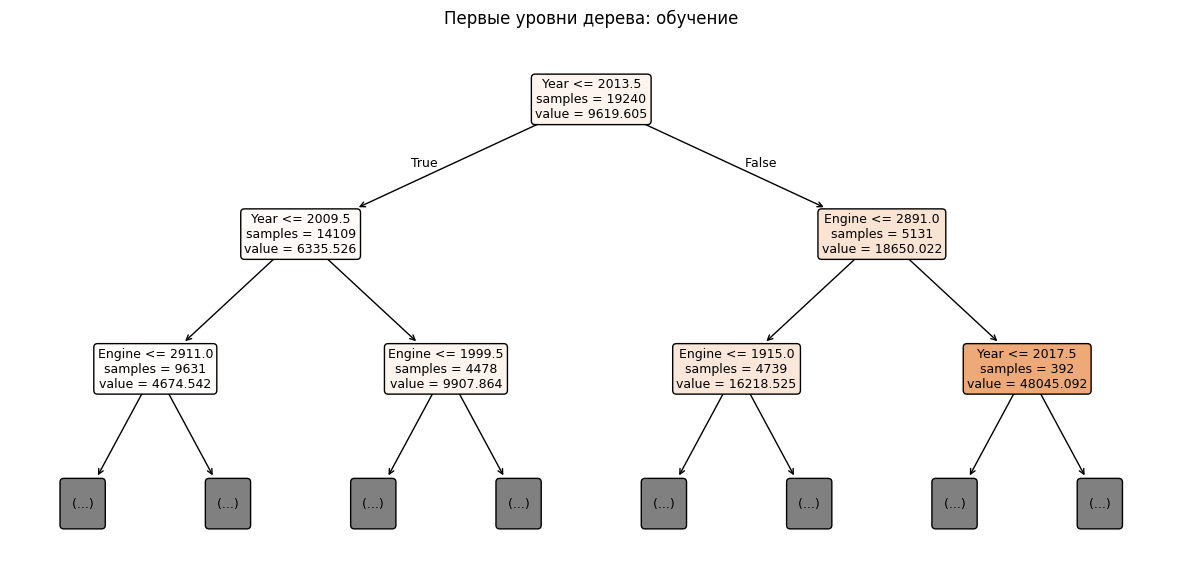

In [9]:
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(small_tree, feature_names=NUMERIC_FEATURES, max_depth=2,
          impurity=False, filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Первые уровни дерева: обучение')
plt.show()


 Верхняя строка вопрос, например про год или пробег. `samples` — сколько обучающих машин дошло до этого узла. `value` — их средняя учебная цена, в евро. Цвет для глаза: темнее обычно там, где средняя выше, точную легенду с экрана не выдумываем.

`max_depth=2` в `plot_tree` рисуем только верх, чтобы текст не слипся. У модели глубина 3, нижний уровень на рисунке может быть спрятан. Спрятанный этаж на картинке не значит, что в модели его нет.

Попросите одного студента пройти путь от корня вниз вслух: «если год старше, идём сюда, потом если пробег больше, цена около…». Это правило, которое дерево выучило, не наша догадка о рынке.


### Случайный лес

Полное имя: **случайный лес**, класс `RandomForestRegressor`.

Одно дерево решений капризно: сдвинули порог — прогноз прыгнул. Лес строит много таких деревьев и усредняет их цены. Прогноз одной машины — среднее ответов всех деревьев, не цена одного листа.

Каждое дерево видит не всю учебную кучу подряд, а случайную подвыборку строк. В регрессионном лесу sklearn на каждом вопросе по умолчанию смотрит **все** признаки. Это не правило «каждое дерево обязано получить свой уникальный столбец». Случайность здесь в первую очередь про набор строк.

`n_estimators=60` — шестьдесят деревьев. `max_depth=10` — каждому нельзя расти бесконечно. `n_jobs=1` — считать в одном потоке, чтобы на учебной машине нагрузка была предсказуемой. `random_state=42` — тот же лес при повторном запуске.


In [10]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(
    n_estimators=60, max_depth=10, random_state=42, n_jobs=1
)
forest.fit(X_train, y_train)
forest_valid_pred = forest.predict(X_valid)
print(f'Лес: Valid MAE = {mean_absolute_error(y_valid, forest_valid_pred):.1f} евро')


Лес: Valid MAE = 2632.1 евро


На этом прогоне четыре Valid MAE: лес **2632.1**, десять соседей **2721.1**, дерево глубины 3 **3507.0**, линейная **4307.8**. Лес первый, отрыв от соседей около 90 евро. Фразу «лес всегда лучше» из этого не делаем: другие ручки могут переставить порядок. Усреднение сглаживает прыжки отдельных деревьев. Плохие признаки, выбросы и переобучение оно не отменяет.

Scaler лесу в этом ноутбуке не ставим: вопросы по-прежнему про один столбец и порог.


## 5. Отдельные шаги знакомы — теперь небольшая общая функция

До сих пор каждый раз писали `fit`, `predict`, MAE. Для девяти вариантов это одна и та же тройка действий. Функция ниже делает **только** её. Параметры не подбирает, в test не заглядывает.

| Аргумент | Что передаём |
|---|---|
| `model` | Один объект: модель или Pipeline |
| `name` | Подпись строки в отчёте |
| `X_fit`, `y_fit` | На чём учим |
| `X_check`, `y_check` | На чём считаем ошибку |

После вызова переданный объект уже обучен. Функция не возвращает копию «как было до fit».


In [6]:
def evaluate_model(model, name, X_fit, y_fit, X_check, y_check):
    model.fit(X_fit, y_fit)
    train_pred = model.predict(X_fit)
    check_pred = model.predict(X_check)
    return {
        'Model': name,
        'Train_MAE': mean_absolute_error(y_fit, train_pred),
        'Valid_MAE': mean_absolute_error(y_check, check_pred),
        'Valid_RMSE': np.sqrt(mean_squared_error(y_check, check_pred))
    }


По строкам. `fit` на учебной части. Потом прогноз на тех же учебных строках и отдельно на проверочных. В словаре три числа: имя, MAE на обучении, MAE на проверке, RMSE на проверке.

RMSE — корень из средней квадратичной ошибки, тоже в евро. Крупный промах бьёт сильнее, чем в MAE. Две метрики могут расставить модели чуть по-разному. В этом ноутбуке **выбор** ниже идёт по Valid MAE. RMSE смотрим, но критерий не меняем по ходу.

Список кандидатов короткий и заранее написан. Не десять глубин подряд «пока не понравится».


In [7]:
candidates = {
    'Median': DummyRegressor(strategy='median'),
    'Linear': Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]),
    'KNN_1': Pipeline([('scale', StandardScaler()), ('model', KNeighborsRegressor(n_neighbors=1))]),
    'KNN_10': Pipeline([('scale', StandardScaler()), ('model', KNeighborsRegressor(n_neighbors=10))]),
    'KNN_30': Pipeline([('scale', StandardScaler()), ('model', KNeighborsRegressor(n_neighbors=30))]),
    'Tree_3': DecisionTreeRegressor(max_depth=3, random_state=42),
    'Tree_10': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Tree_full': DecisionTreeRegressor(random_state=42),
    'Forest_10': RandomForestRegressor(n_estimators=60, max_depth=10, random_state=42, n_jobs=1)
}


NameError: name 'DummyRegressor' is not defined

Что здесь разное, проговорите по группам.

**Median** — `DummyRegressor`, константа-медиана. Всем одна цена, медиана train. Признаки не смотрит.

**Linear** — `LinearRegression`, линейная регрессия. Одна формула по четырём числам, scaler внутри Pipeline.

**KNN_1, KNN_10, KNN_30** — один и тот же `KNeighborsRegressor`, метод k ближайших соседей. Меняется только k. Один сосед повторяет цену ближайшей учебной машины. Тридцать соседей сильнее усредняют и меньше дёргаются. Scaler у каждого свой, внутри своего pipeline.

**Tree_3** — `DecisionTreeRegressor`, дерево решений глубины 3. **Tree_10** — то же дерево, глубже. **Tree_full** без `max_depth` растёт, пока листья не станут очень чистыми. Это самый гибкий из трёх.

**Forest_10** — `RandomForestRegressor`, случайный лес из раздела 4. Имя «10» в подписи — про ограничение глубины каждого дерева, не про число соседей. Деревьев по-прежнему 60.

Масштаб стоит только там, где расстояние или линейные коэффициенты. У деревьев и леса сырые единицы.


In [13]:
results = []
for name, model in candidates.items():
    result = evaluate_model(model, name, X_train, y_train, X_valid, y_valid)
    results.append(result)

comparison_06 = pd.DataFrame(results).sort_values('Valid_MAE')
display(comparison_06.round(1))


,Model,Train_MAE,Valid_MAE,Valid_RMSE
8,Forest_10,2220.1,2632.1,5682.7
4,KNN_30,2628.8,2715.0,5664.0
3,KNN_10,2487.1,2721.1,5617.8
6,Tree_10,2201.5,2759.1,6135.4
7,Tree_full,363.7,3309.7,7054.0
2,KNN_1,399.5,3330.1,7129.5
5,Tree_3,3485.6,3507.0,6412.3
1,Linear,4306.7,4307.8,7685.1
0,Median,5967.0,5944.5,10535.9


`items()` отдаёт подпись и объект. Цикл учит каждый вариант на train и мерит на valid. Список словарей становится таблицей. `sort_values('Valid_MAE')` поднимает меньшую ошибку наверх. Все MAE и RMSE здесь в евро.

**Train_MAE** — насколько модель попадает в машины, которые уже видела. **Valid_MAE** — в машины, которые при обучении прятали. Нам для выбора важна вторая. Маленький train при большом valid зазубрила. Оба большие значит правило слабое или данные шумные. Близкие числа ещё не «модель готова навсегда».

Таблица этого файла, сверху меньшая Valid MAE:

| Модель | Train MAE | Valid MAE |
|---|---:|---:|
| Forest_10 | 2220.1 | 2632.1 |
| KNN_30 | 2628.8 | 2715.0 |
| KNN_10 | 2487.1 | 2721.1 |
| Tree_10 | 2201.5 | 2759.1 |
| Tree_full | 363.7 | 3309.7 |
| KNN_1 | 399.5 | 3330.1 |
| Tree_3 | 3485.6 | 3507.0 |
| Linear | 4306.7 | 4307.8 |
| Median | 5967.0 | 5944.5 |

По Valid MAE побеждает лес. Медиана хуже всех, около 5944: её обыграли все. Линейная почти одинаково врёт на train и valid, около 4307: не зазубрила, правило слабое. Тридцать соседей и десять почти рядом, 2715 и 2721. Один сосед хуже обоих.

**KNN_1.** Train MAE около **399.5**, не ноль. Ноль получился бы, если у каждой учебной строки свои признаки: ближайший сосед — она сама. Здесь у части машин четыре числа совпадают, а цены нет. Это те же «двойники» с расстоянием 0, что в таблице соседей. На train модель иногда берёт чужую цену. 399 на обучении при 3330 на valid — зазубривание, не победа.

**Деревья.** `Tree_3`: train 3485.6 и valid 3507.0, почти рядом. `Tree_10`: train упал до 2201.5, valid до 2759.1 — глубина помогла и на проверке. `Tree_full`: train **363.7**, valid **3309.7**. Учебная ошибка самая маленькая из трёх, проверочная хуже, чем у дерева глубины 10. Это строка задания: меньший train не дал меньший valid. Письменную формулировку студенты пишут сами.

График — те же три дерева, не поиск «лучшей глубины между точками».


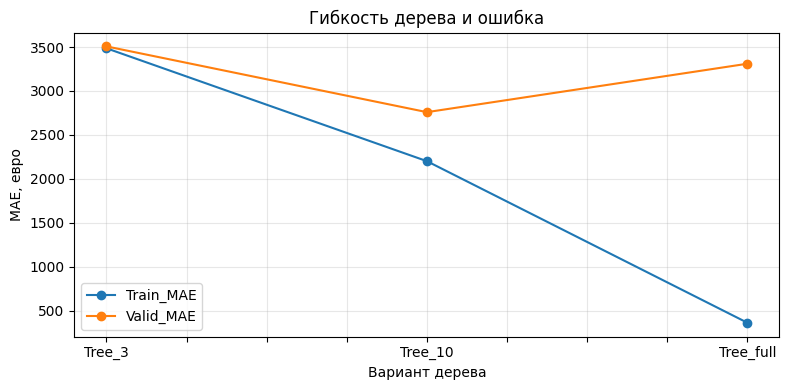

In [14]:
tree_rows = pd.DataFrame(results).set_index('Model').loc[['Tree_3', 'Tree_10', 'Tree_full']]
ax = tree_rows[['Train_MAE', 'Valid_MAE']].plot(marker='o', figsize=(8, 4))
ax.set(xlabel='Вариант дерева', ylabel='MAE, евро', title='Гибкость дерева и ошибка')
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


Две линии: ошибка на train и на valid. Ось X — три заранее выбранных варианта, не все целые глубины от 1 до 30. Про промежуточную глубину 7 график ничего не доказал: её в списке не было.

На графике у `Tree_full` линия train уходит вниз, к 364 евро, а valid поднимается к 3310. Самая гибкая из трёх на проверке не лучшая: лучше `Tree_10`. Мини-задание студенты формулируют своими словами. Если после графика захочется добавить глубину 15 и снова смотреть valid — это уже новая настройка на valid. Test для этого не открываем.


## 6. Кросс-валидация: несколько внутренних проверок

Один разрез valid мог оказаться удачным: в нём случайно много «обычных» машин. Или неудачным. Кросс-валидация делает несколько таких проверок **внутри train**.

Берём только `X_train`. Внешние valid и test в этом разделе не участвуют. Иначе мы бы дважды потратили valid: и как экзамен для выбора, и как кусок внутренней проверки.

`KFold` на 3 блока. Каждый шаг: два блока учат, один проверяет. Модель на каждом шаге создаётся заново.

| Шаг | Учим | Проверяем |
|---|---|---|
| 1 | блоки 2 и 3 | блок 1 |
| 2 | блоки 1 и 3 | блок 2 |
| 3 | блоки 1 и 2 | блок 3 |

Каждая строка train ровно один раз попадает в проверку. Среднее трёх MAE — сводка этого протокола. Разброс между блоками показывает, насколько шаги непохожи. Это не доверительный интервал и не обещание ошибки на будущем рынке.

Три блока, не десять: на паре успеваем увидеть идею. Для знакомства хватает.


In [15]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=3, shuffle=True, random_state=42)
for number, (fit_positions, check_positions) in enumerate(cv.split(X_train), start=1):
    print(f'Блок {number}: обучение {len(fit_positions)}, проверка {len(check_positions)}')


Блок 1: обучение 12826, проверка 6414
Блок 2: обучение 12827, проверка 6413
Блок 3: обучение 12827, проверка 6413


`shuffle=True` перемешивает строки train перед нарезкой, `random_state` фиксирует перемешивание. `split` отдаёт **позиции**, номера с нуля внутри `X_train`, не индексы Pandas.

На экране три строки: обучение 12826, потом дважды 12827; проверка 6414, потом дважды 6413. Проверочный кусок — треть train, учебный — две трети. Даты объявлений в файле нет, поэтому режем случайно, не «прошлое учит, будущее проверяет».


In [16]:
cv_result = cross_validate(
    candidates['KNN_10'], X_train, y_train,
    cv=cv, scoring='neg_mean_absolute_error',
    return_train_score=True, n_jobs=1
)
fold_mae = -cv_result['test_score']
display(pd.DataFrame({'Fold': [1, 2, 3], 'MAE, евро': fold_mae}).round(1))
print(f'Средняя MAE: {fold_mae.mean():.1f}; SD по блокам: {fold_mae.std():.1f} евро')


,Fold,"MAE, евро"
0,1,2890.4
1,2,2685.3
2,3,2780.1


Средняя MAE: 2785.3; SD по блокам: 83.8 евро


Почему оценка называется `neg_mean_absolute_error`. В sklearn единый договор: **больший** score — лучше. MAE устроена наоборот: меньше евро — лучше. Минус перед MAE переворачивает шкалу. В отчёте минус снимаем: `fold_mae = -cv_result['test_score']`, снова евро.

Три MAE десяти соседей на блоках: **2890.4**, **2685.3** и **2780.1**. Среднее **2785.3**, SD около **83.8** евро. Скачка «один блок вдвое хуже» нет. Valid MAE тех же десяти соседей была 2721.1: близко к 2785, но не то же число.

Ключ `test_score` здесь — внутренний блок CV. Это не наш `X_test` и не valid из раздела 1. Имя историческое, его легко перепутать. На паре скажите это вслух отдельно.

Pipeline на каждом блоке учится с нуля, и scaler тоже. Среднее и разброс считаются только по строкам, которые на этом шаге учебные. Проверочный блок в среднее не входит.

Если сначала масштабировать **весь** `X_train`, а потом запустить CV по готовому массиву, проверочные строки уже повлияли на среднее. Это та же утечка, только внутри train. Поэтому в список кандидатов scaler положен внутрь Pipeline, а не сделан один раз снаружи.

Вопрос в ноутбуке: зачем scaler внутри Pipeline, если код и так короче. Подсказка на слух: дело не в краткости. На каждом блоке CV преобразование должно учиться только на учебном куске этого блока. Иначе проверка подсказывает подготовке.

Дальше те же три блока у двух моделей, чтобы сравнение было честным.


In [17]:
cv_rows = []
for name in ['Linear', 'KNN_10']:
    r = cross_validate(candidates[name], X_train, y_train, cv=cv,
                       scoring='neg_mean_absolute_error', n_jobs=1)
    values = -r['test_score']
    cv_rows.append({'Model': name, 'CV_MAE': values.mean(), 'CV_SD': values.std()})
cv_summary = pd.DataFrame(cv_rows)
display(cv_summary.round(1))


,Model,CV_MAE,CV_SD
0,Linear,4313.5,51.7
1,KNN_10,2785.3,83.8


Одинаковые блоки, разный алгоритм. `CV_MAE` — среднее по блокам, `CV_SD` — насколько блоки разъехались.

На экране Linear: CV_MAE **4313.5**, SD **51.7**. KNN_10: CV_MAE **2785.3**, SD **83.8**. Соседи снова ниже примерно на 1500 евро, как на valid (4307.8 против 2721.1). Порядок не перевернулся. Цифры не совпали один в один: внутри CV учатся два блока, не весь train. Отчёт, где цифра красивее, не выбираем. Для финала по-прежнему минимальная Valid MAE. CV здесь только проверяет, что сравнение линейной модели и десяти соседей держится на трёх нарезках.


## 7. Выбрали вариант — теперь одна итоговая проверка

Критерий зафиксирован до теста: среди кандидатов раздела 5 берём строку с минимальной Valid MAE. Не «у кого красивее график» и не «у кого лучше CV, если valid не понравилась».


In [18]:
best_name = comparison_06.iloc[0]['Model']
print('Выбран вариант:', best_name)
print('Критерий выбора: минимальная Valid MAE')


Выбран вариант: Forest_10
Критерий выбора: минимальная Valid MAE


Таблица уже отсортирована по Valid MAE, поэтому `iloc[0]` — верхняя строка, меньшая ошибка. На экране имя **Forest_10**: это случайный лес `RandomForestRegressor`, 60 деревьев, глубина каждого 10. Valid MAE 2632.1. Мы запомнили **имя алгоритма и его ручки**, не «самый удачный прогноз одной машины».

После выбора модель можно заново учить на train вместе с valid. Настройки уже названы, valid свою роль экзаменатора отыграла. Scaler, если он внутри, тоже учится заново на этих 80%. Test по-прежнему в стороне.

Зачем доучивать на 80%, а не оставить модель, которая училась только на 60%. Ей можно показать больше примеров **с уже выбранными ручками**. Сравнивать новую учебную ошибку со старой Train MAE нельзя: состав строк другой, это другой экзамен.


In [19]:
from sklearn.base import clone

X_development = pd.concat([X_train, X_valid])
y_development = pd.concat([y_train, y_valid])
final_model = clone(candidates[best_name])
final_model.fit(X_development, y_development)
print('Для итогового обучения:', X_development.shape)


Для итогового обучения: (25653, 4)


`clone` копирует ручки: глубину, число соседей, шаги pipeline. Выученные коэффициенты и средние scaler **не** копирует. Объект свежий, `fit` честный.

Почему не взять `candidates[best_name]` как есть. Его уже учили на одном только train внутри `evaluate_model`. Повторный `fit` тоже сработал бы, но `clone` делает намерение явным: это новый экземпляр с теми же настройками.

`concat` склеивает строки. Индексы Pandas сохраняются, одна и та же машина не должна оказаться в двух кусках: мы это проверяли ещё в пятой работе.

На экране форма: около 80% исходных строк и 4 признака.

Теперь один раз test. В `predict` цены не передаём. `y_test` достаём только чтобы померить промах. Медиану тоже учим заново на тех же 80%, иначе ориентир жил на другой куче, чем финальная модель.


In [20]:
final_test_pred = final_model.predict(X_test)
final_baseline = DummyRegressor(strategy='median')
final_baseline.fit(X_development, y_development)
baseline_test_pred = final_baseline.predict(X_test)

test_summary = pd.DataFrame([
    {'Model': best_name,
     'Test_MAE': mean_absolute_error(y_test, final_test_pred),
     'Test_RMSE': np.sqrt(mean_squared_error(y_test, final_test_pred)),
     'Test_R2': r2_score(y_test, final_test_pred)},
    {'Model': 'Median',
     'Test_MAE': mean_absolute_error(y_test, baseline_test_pred),
     'Test_RMSE': np.sqrt(mean_squared_error(y_test, baseline_test_pred)),
     'Test_R2': r2_score(y_test, baseline_test_pred)}
])
display(test_summary.round(3))


,Model,Test_MAE,Test_RMSE,Test_R2
0,Forest_10,2732.933,7284.939,0.511
1,Median,5862.723,10765.819,-0.068


Три колонки. **Test_MAE** — средний модуль промаха в евро. **Test_RMSE** — та же идея, крупные промахи тяжелее. **Test_R2** — насколько квадраты ошибок меньше, чем если бы всем называли среднюю цену **этой тестовой** части. 1 — идеально по этой формуле, 0 — как константа-среднее, ниже нуля — хуже константы. Это не «доля угаданных машин».

На этом тесте лес: MAE **2732.9** евро, RMSE **7284.9**, R² **0.511**. Медиана на тех же строках: MAE **5862.7**, RMSE **10765.8**, R² **−0.068**. Лес обыграл «одну цену на всех» примерно на 3100 евро. 2733 близко к valid 2632: на отложенных строках модель не развалилась. R² 0.51 — квадраты ошибок меньше, чем у константы-среднего, до единицы далеко. Отрицательный R² медианы: она хуже, чем просто назвать среднюю цену этого теста.

RMSE 7285 при MAE 2733 — хвост тяжёлый: отдельные промахи намного больше типичного. Хорошая цифра не обещает тот же промах на будущем рынке, другой стране или машинах, которых в файле не было.

Дальше тестовые ошибки можно **смотреть**, чтобы описать, где врёт. Подкрутить глубину или число соседей, чтобы именно этот test стал красивее, нельзя. Если так сделали, test стал частью разработки. Для честной итоговой оценки нужен новый, ещё не виденный набор. В этой работе его нет, поэтому назад не идём.

Таблица крупных промахов и срез по году.


In [21]:
test_predictions = df.loc[X_test.index, ['Make', 'Model', 'Year', 'Distance', 'Engine', 'Price']].copy()
test_predictions['Prediction'] = final_test_pred
test_predictions['Error'] = test_predictions['Prediction'] - test_predictions['Price']
test_predictions['Abs_error'] = test_predictions['Error'].abs()
display(test_predictions.nlargest(10, 'Abs_error'))
error_by_year = test_predictions.groupby('Year').agg(
    n=('Abs_error', 'size'), MAE=('Abs_error', 'mean'), Bias=('Error', 'mean')
)
display(error_by_year.sort_values('MAE', ascending=False).head(10).round(1))


,Make,Model,Year,Distance,Engine,Price,Prediction,Error,Abs_error
6793,KIA,Sportage,2018,46327.0,1600.0,17700.0,276227.584944,258527.584944,258527.584944
11832,Toyota,Prius Prime,2018,47000.0,1800.0,14600.0,212732.845001,198132.845001,198132.845001
11660,Toyota,Land Cruiser Prado,2012,10005.0,3000.0,200000.0,34255.548228,-165744.451772,165744.451772
26974,Skoda,Superb,2018,47500.0,1600.0,20500.0,164762.088786,144262.088786,144262.088786
29107,Rare,Altele,2009,120000.0,2000.0,120000.0,6770.228682,-113229.771318,113229.771318
4680,Mercedes,A Class,2006,166557.0,1689.0,111000.0,3703.294300,-107296.705700,107296.705700
15579,Mercedes,M Class,2010,120000.0,3000.0,120000.0,21122.823022,-98877.176978,98877.176978
20201,Rare,75,2005,200000.0,2500.0,95000.0,6382.189982,-88617.810018,88617.810018
3315,Renault,ZOE,2016,21200.0,4100.0,11899.0,96129.323246,84230.323246,84230.323246
18548,Rare,Xf,2014,156466.0,2200.0,100000.0,19325.302005,-80674.697995,80674.697995


,n,MAE,Bias
Year,,,
2020,39,12574.3,2182.8
2021,28,11724.6,2652.1
2018,175,8601.0,2518.1
1971,1,7695.3,7695.3
2019,72,7578.5,576.5
2017,269,4830.2,376.8
1979,1,4458.2,-4458.2
1974,4,4294.4,-3438.2
2016,349,4265.8,228.1


Берём строки теста из исходной таблицы: марка и модель здесь для глаз, в обучении четырёх чисел их не было. `Error` со знаком: плюс — модель назвала дороже правды. `Abs_error` — величина промаха. `nlargest` показывает десять самых больших по модулю.

Десять худших промахов — не «чуть мимо». Kia Sportage 2018 за 17700 модель оценила примерно в 276000. Toyota Prius Prime 2018 за 14600 — примерно в 213000. В другую сторону Land Cruiser Prado с ценой 200000 получил прогноз около 34000. Четырёх чисел мало: редкая цена или другая комплектация ломает прогноз леса.

По году: `n` — сколько тестовых машин этого года, `MAE` — средний модуль, `Bias` — среднее со знаком. Наверху списка не «пара старых машин», а свежие годы. 2020: n=39, MAE около 12574. 2021: n=28, около 11725. 2018: n=175, около 8601. Плюсовой Bias значит: в среднем модель эти годы завышает. Рядом 1971 год с **одной** машиной и MAE около 7695. Большое число при n=1 не описывает весь такой год. `n` читаем раньше, чем пугаемся MAE. Большой промах сам по себе не доказывает опечатку в файле: может не хватать признака.


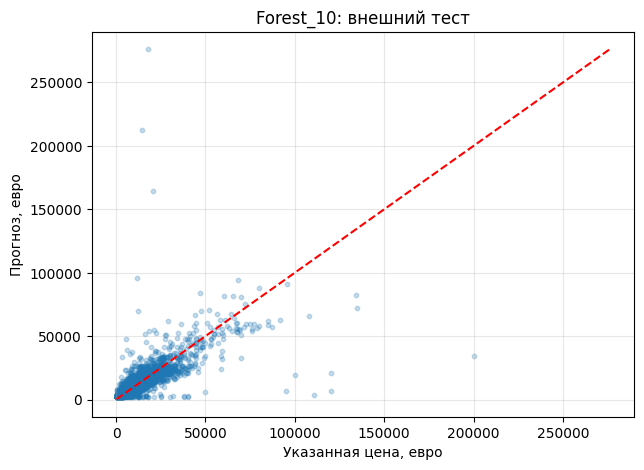

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, final_test_pred, s=10, alpha=.25)
low = min(y_test.min(), final_test_pred.min())
high = max(y_test.max(), final_test_pred.max())
ax.plot([low, high], [low, high], 'r--')
ax.set(title=f'{best_name}: внешний тест', xlabel='Указанная цена, евро', ylabel='Прогноз, евро')
ax.grid(alpha=.3)
plt.show()


Ось X — цена из объявления, ось Y — прогноз. Пунктир — совпадение. Точка выше пунктира — завышение, ниже — занижение. Далёкие точки сверху — те самые прогнозы на сотни тысяч при цене объявления около 15–20 тысяч. Из-за них RMSE 7285 гораздо больше MAE 2733.

В ноутбуке просят три наблюдения своими словами. Готовый абзац за студентов не диктуем. Разброс на картинке сам по себе не доказывает фразу «нужна модель сложнее»: в основном маршруте не было марки и состояния, и как раз они видны в строках с огромным промахом.


## 8. Сохранение и запуск на новой строке

Модель в памяти умрёт вместе с ядром. `joblib` записывает объект Python на диск: алгоритм, ручки и всё, что он выучил. Если это pipeline, scaler с его средними едет внутри того же файла. Отдельно «не забудь потом масштабировать» хранить не нужно.

Рядом кладём короткую подпись: какое имя выбрали, какие столбцы, в каком порядке, цена в евро, версия sklearn, правило выбора. Через месяц по файлу `.joblib` это уже не прочитать. Чужой файл модели не загружаем: это исполняемый объект, не картинка.


In [23]:
import joblib
import json

joblib.dump(final_model, 'cars_price_model.joblib')
metadata = {'selected_model': best_name, 'numeric_features': NUMERIC_FEATURES,
            'price_unit': 'EUR', 'sklearn_version': sklearn.__version__,
            'selection_rule': 'minimum validation MAE',
            'reference_year_for_km_year': 2022}
Path('cars_price_model_metadata.json').write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8'
)
comparison_06.to_csv('lab06_validation_comparison.csv', index=False)
cv_summary.to_csv('lab06_cv_summary.csv', index=False)
test_summary.to_csv('lab06_test_summary.csv', index=False)
test_predictions.rename_axis('dataset_row_id').reset_index().to_csv('lab06_test_predictions.csv', index=False)


Пять файлов. Модель, подпись, таблица valid-сравнения, сводка CV, итог теста, прогнозы по тестовым строкам. `reference_year_for_km_year` напоминает, от какого года в подготовке данных считали километры в год. Без той же подготовки столбцы «те же по имени» могут означать другое.

Порядок колонок в `NUMERIC_FEATURES` — часть контракта. Список из четырёх чисел без подписи «это год, это пробег» в `predict` отдавать нельзя: модель прочитает их как столбцы слева направо.


In [24]:
loaded_model = joblib.load('cars_price_model.joblib')
new_car = X_test.iloc[[0]].copy()
display(new_car)
print(f'Оценка цены: {loaded_model.predict(new_car)[0]:.1f} евро')


,Year,Distance,Engine,km_year
6292,2017,32935.0,3000.0,6587.0


Оценка цены: 55316.7 евро


Загрузили с диска и спросили цену. Для pipeline на вход сырые единицы, руками scaler не вызываем. На экране машина 2017 года, пробег 32935, объём 3000: оценка около **55316.7** евро. Это проверка, что файл открывается. Строка уже из теста, второй экзамен из неё не делаем.

Честно про эту строку. Это первая строка **уже использованного теста**, не новая машина с улицы. Мы проверяем, что файл открывается и `predict` живой. Второй независимой оценки это не создаёт. Настоящая итоговая цифра уже лежит в `test_summary`.

Одинаковые данные → несколько алгоритмов и ручек → выбор по valid → один раз test на модели, доученной на 80% → файл, который повторяет этот `predict`.


## 9. Дополнительно: текстовые категории, по одному шагу

В основном маршруте входы — четыре числа. Марка в них не входила, хотя на ошибках теста мы её уже видели глазами. У марки нет порядка «BMW больше Toyota». Если записать BMW=1, Toyota=2, Volkswagen=3, линейная модель решит, что между ними равные шаги, как между годами. Это выдуманная линейка.

One-hot делает иначе. На каждую марку — свой столбец 0/1. У строки Toyota горит единица в столбце Toyota и нули в остальных. Никакого «Toyota на единицу больше BMW».

Сначала крошечный пример, не вся таблица.


In [25]:
from sklearn.preprocessing import OneHotEncoder

toy_categories = pd.DataFrame({'Make': ['Toyota', 'BMW', 'Toyota']})
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(toy_categories)
toy_encoded = encoder.transform(toy_categories)
display(pd.DataFrame(toy_encoded, columns=encoder.get_feature_names_out()))


,Make_BMW,Make_Toyota
0,0.0,1.0
1,1.0,0.0
2,0.0,1.0


`fit` запоминает, какие марки встретил: здесь две. `transform` строит таблицу индикаторов. Две строки Toyota получают одинаковый код. Цена не использовалась: кодируем вход, не ответ.

`sparse_output=False` — обычный плотный массив, чтобы `display` показал нули и единицы. На большой таблице нулей большинство, разреженный формат хранит в основном единицы и экономит память. Для просмотра на паре плотный массив понятнее.

Новая марка, которой в `fit` не было.


In [26]:
unknown_make = pd.DataFrame({'Make': ['UnknownBrand']})
print(encoder.transform(unknown_make))


[[0. 0.]]


`handle_unknown='ignore'` не роняет программу. Для неизвестной марки все индикаторы — нули. Модель не узнала свойства этой марки. Она получает «ни одна из знакомых галочек не стоит». Отсутствие красной ошибки — не надёжный прогноз. Скажите это у экрана и не превращайте в готовый абзац за студентов: в ноутбуке как раз этот вопрос.

Теперь поля из нашего файла. Марка, модель, кузов, топливо. Если в таблице осталась исходная марка `Make_original`, берём её: в подготовке редкие марки могли слить в одну подпись `Rare`, и тогда one-hot видит уже испорченный список.


In [27]:
CATEGORY_FEATURES = ['Make', 'Model', 'Style', 'Fuel_type']
X_mixed = df[NUMERIC_FEATURES + CATEGORY_FEATURES].copy()
if 'Make_original' in df:
    X_mixed['Make'] = df['Make_original']
X_mixed_train = X_mixed.loc[X_train.index]
X_mixed_valid = X_mixed.loc[X_valid.index]
display(X_mixed_train.head(3))


,Year,Distance,Engine,km_year,Make,Model,Style,Fuel_type
22222,2007,187000.0,1400.0,12466.666667,Toyota,Corolla,Hatchback,Diesel
3091,2014,30500.0,2000.0,3812.500000,Volkswagen,Golf,Hatchback,Petrol
24316,2009,244140.0,2200.0,18780.000000,Mercedes,Vito,Minivan,Diesel


Те же машины, те же индексы train и valid, шире вход. Ответы `y_train` не пересобираем.

Сюда не добавляем «среднюю цену марки» или «среднюю цену года», посчитанную по всей таблице. Такое число уже содержит цены valid и test. Модель прочитает ответ с полей экзамена. Это утечка, даже если столбец выглядит невинно.

Дальше двум типам колонок нужны разные действия. Числа — scaler. Категории — one-hot. `ColumnTransformer` держит ветки рядом.


In [28]:
from sklearn.compose import ColumnTransformer

mixed_preprocessor = ColumnTransformer([
    ('numbers', StandardScaler(), NUMERIC_FEATURES),
    ('categories', OneHotEncoder(handle_unknown='ignore'), CATEGORY_FEATURES)
], remainder='drop')
mixed_preprocessor.fit(X_mixed_train)
mixed_sample = mixed_preprocessor.transform(X_mixed_train.iloc[:3])
print('Три строки после преобразования:', mixed_sample.shape)
print('Первые имена:', mixed_preprocessor.get_feature_names_out()[:12])


Три строки после преобразования: (3, 767)
Первые имена: ['numbers__Year' 'numbers__Distance' 'numbers__Engine' 'numbers__km_year'
 'categories__Make_Audi' 'categories__Make_BMW'
 'categories__Make_Chevrolet' 'categories__Make_Dacia'
 'categories__Make_Ford' 'categories__Make_Honda'
 'categories__Make_Hyundai' 'categories__Make_KIA']


Тройка в списке: бирка, преобразователь, какие колонки он ест. `remainder='drop'` выкидывает всё, что не назвали. Иначе в модель уехал бы лишний столбец.

`fit` только на train. На экране форма трёх строк — **(3, 767)**: из четырёх чисел и текстовых полей получилось 767 столбцов. Первые имена: Year, Distance, Engine, km_year, дальше Make_Audi, Make_BMW и остальные марки. Три строки в `mixed_sample` — просто посмотреть форму, в обучение pipeline их не подсовываем.


In [29]:
mixed_pipeline = Pipeline([
    ('prepare', mixed_preprocessor),
    ('model', LinearRegression())
])
mixed_pipeline.fit(X_mixed_train, y_train)
mixed_valid_pred = mixed_pipeline.predict(X_mixed_valid)
print(f'Численные + категории, Valid MAE: {mean_absolute_error(y_valid, mixed_valid_pred):.1f} евро')
print(f'Только численные, Valid MAE: {linear_valid_mae:.1f} евро')


Численные + категории, Valid MAE: 3187.1 евро
Только численные, Valid MAE: 4307.8 евро


Важный порядок. Мы собрали pipeline из **уже обученного** препроцессора и новой регрессии. На `fit` pipeline прогонит шаги ещё раз и переобучит их на `X_mixed_train`. Это нормально, данные те же. Путать нельзя другое: не надо вручную скормить модели уже готовый `mixed_sample` и думать, что это другой эксперимент.

На valid категории снизили MAE линейной модели с **4307.8** до **3187.1**, примерно на 1100 евро. Это лучше голой прямой и хуже леса с 2632.1 на тех же четырёх числах. В уже выбранный лес эту модель не подмешиваем: тест открыт. Для марки, которой не было в train, индикаторы будут нули, и 3187 это не обещает.


## 10. Дополнительно: логарифм цены

Обычная линейная модель складывает «коэффициент × признак» и получает евро напрямую. Дорогие машины тянут прямую сильнее: промах в 10 тысяч на редком авто для квадратов ошибок огромный.

Идея: учить не евро, а `log(Price)`, а наружу вернуть `exp`. Логарифм сжимает большие цены. Нужны строго положительные цены, у нас предохранитель это уже проверил.

Мерить MAE и RMSE надо **после** возврата в евро. Иначе сравниваем «ошибку в логарифмах» с «ошибкой в евро» и объявляем победителя по разным линейкам.

`TransformedTargetRegressor` хранит преобразование **ответа** рядом с моделью. Признаки он не трогает. На `fit` применяет `log` к y, учит внутреннюю модель, на `predict` делает `exp` и отдаёт евро.


In [30]:
from sklearn.compose import TransformedTargetRegressor

log_price_model = TransformedTargetRegressor(
    regressor=Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]),
    func=np.log, inverse_func=np.exp
)
log_price_model.fit(X_train, y_train)
log_valid_pred = log_price_model.predict(X_valid)
print(f'Логарифм цены, Valid MAE: {mean_absolute_error(y_valid, log_valid_pred):.1f} евро')
print(f'Логарифм цены, Valid RMSE: {np.sqrt(mean_squared_error(y_valid, log_valid_pred)):.1f} евро')


Логарифм цены, Valid MAE: 3137.2 евро
Логарифм цены, Valid RMSE: 6894.9 евро


Новый объект, отдельное имя. `final_model` не трогаем.

`predict` уже в евро. Второй `exp` был бы ошибкой: получились бы экспоненты от евро, космические числа.

На valid MAE около **3137.2** евро, RMSE около **6894.9**. Обычная линейная была 4307.8, её RMSE около 7685. Логарифм на этой проверке помог прямой и до леса (2632.1) не дошёл.

Честная оговорка для первого курса, одной фразой. Среднее в логарифмах после `exp` не обязано совпасть со средним в евро. Мы и не обещаем «несмещённую среднюю цену». Сравниваем MAE и RMSE уже в евро.


## 11. Дополнительно: полиномиальные признаки

Можно не менять алгоритм, а расширить вход. `PolynomialFeatures(degree=2)` добавляет квадраты и произведения пар. Год остаётся, рядом появляются «год в квадрате» и «год × пробег».

Модель по-прежнему линейная, но уже по **новым** столбцам. По исходным году и пробегу связь может быть кривой. Степень 2 — учебный шаг. Степень 3 и перебор десятка вариантов на паре не запускаем: столбцов становится много, valid легко зазубрить.

`include_bias=False` не добавляет столбец из единиц. Свободный член и так есть у `LinearRegression`. Два свободных члена сразу не нужны.

Порядок в конвейере: сначала scaler исходных четырёх чисел, потом степени. Квадрат пробега в сырых километрах — огромное число. После масштаба промежуточные значения спокойнее. Все вопросы точности на больших степенях это не снимает, для степени 2 на паре достаточно.


In [31]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_model = Pipeline([
    ('scale', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
])
polynomial_model.fit(X_train, y_train)
polynomial_valid_pred = polynomial_model.predict(X_valid)
print('Число новых входов:', polynomial_model.named_steps['poly'].n_output_features_)
print(f'Полином, Valid MAE: {mean_absolute_error(y_valid, polynomial_valid_pred):.1f} евро')


Число новых входов: 14
Полином, Valid MAE: 3209.8 евро


Число новых входов — **14**: четыре исходных признака, их квадраты и попарные произведения. Цена здесь остаётся в евро. Это не логарифм из раздела 10: там меняли ответ, здесь меняем признаки.

Valid MAE полинома около **3209.8**. На той же valid: обычная линейная **4307.8**, логарифм цены **3137.2**, полином **3209.8**. Все три лучше голой прямой. Лучший из трёх — логарифм, и он слабее леса. «Преобразование всегда улучшает модель» из этой тройки не следует: они улучшили одну линейную модель и не обогнали уже выбранный лес. Письменный вывод студенты формулируют сами.


## 12. Дополнительно: тот же интерфейс в классификации

Короткий пример в стороне от машин. Данные Iris: три вида цветка, признаки — измерения лепестков. Цель — **класс**, не цена. Наши `X_train` и `final_model` этот код не переписывает: все имена с приставкой `iris_`.

Полное имя: **логистическая регрессия**, класс `LogisticRegression`. По слову «регрессия» она похожа на модель цены, по роли это классификатор: прикидывает, к какому классу объект ближе, и на выходе отдаёт метку класса, не евро. `max_iter=1000` — сколько шагов подбора разрешено, чтобы учебный пример спокойно сошёлся.

`stratify=iris_y` при разрезе держит доли классов в train и test похожими на полный набор. Для цены машины так не делают: у непрерывного евро нет трёх классов, доли держать нечего.

Accuracy — доля верных меток. Для цены её нет: прогноз 10 000 при правде 10 500 — не «не тот класс», а промах в евро.


In [32]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris_X, iris_y = load_iris(return_X_y=True, as_frame=True)
iris_X_train, iris_X_test, iris_y_train, iris_y_test = train_test_split(
    iris_X, iris_y, test_size=.3, random_state=42, stratify=iris_y
)
iris_model = Pipeline([('scale', StandardScaler()),
                       ('model', LogisticRegression(max_iter=1000))])
iris_model.fit(iris_X_train, iris_y_train)
iris_pred = iris_model.predict(iris_X_test)
print(f'Доля правильных классов Iris: {accuracy_score(iris_y_test, iris_pred):.3f}')


Доля правильных классов Iris: 0.911


На Iris доля верных классов около **0.911**. Это 91% меток цветка, не евро и не наша цена.

Зачем этот заход в конце. Интерфейс тот же, что весь семестр: `Pipeline`, `fit`, `predict`. Меняется смысл ответа и метрика. Accuracy на цену автомобиля не переносим.

Последняя ячейка блокнота — интерактивный график тестовых ошибок через Plotly, если библиотека стоит. Точки те же, что уже посчитали. Наведение показывает марку, год, промах. Это просмотр для вопросов «что исследовать дальше», не новый подбор и не повод открыть ручки снова.
